In [1]:
import sys
from google.colab import drive

drive.mount('/content/drive')
sys.path.insert(0, '/content/drive/MyDrive/predictive_learning')

import networks
from networks import LateralInhibitoryLayer
import generators
from generators import MultipleSpeedCrossingBar, CifarImagePatches
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output


def cosine_similarity(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))


MessageError: Error: credential propagation was unsuccessful

# Natural Images (ZCA whitened 16x16 patches of CIFAR dataset)

In [ ]:
screen_size = 16
gen_params = CifarImagePatches.default_params()
gen_params['patch_size'] = screen_size
gen_params['whitening'] = "zca"
gen_params['cache_dir'] = "/content/drive/MyDrive/data"
np.random.seed(42)
gen = CifarImagePatches(gen_params)

# plot some images from generator
fig, axes = plt.subplots(1, 10, figsize=(15, 3))
np.random.seed(42)
gen.set_random_position()
img = gen.get_current_frame()
for i in range(10):
    gen.set_random_position()
    img = gen.get_current_frame()
    axes[i].imshow(img.squeeze(), cmap="gray")
    axes[i].axis("off")
    plt.colorbar(axes[i].imshow(img.squeeze(), cmap="gray"), ax=axes[i], fraction=0.046, pad=0.04)

 83%|████████▎ | 142M/170M [11:15<01:58, 242kB/s]

## Predictive Network

Here we initialize and train a network with 500 units that updates the feed-forward weights according to the predictive rule.

In [ ]:
#create a non-linear network with 500 units
network_params = LateralInhibitoryLayer.default_hparams((gen.x_size*2, gen.y_size, 1))
network_params['activation'] = 'relu'
network_params['num_units_y'] = 500
network_params['gradient'] = 'voltage-jax'
network_params['w_update'] = 'perceptron'
network_params['w_rectify'] = True
network_params['w_seed'] = 42
network_params['w_init'] = 'random'
network_params['w_dynamic'] = True
network_params['m_update'] = 'hebbian'
network_params['m_rectify'] = True
network_params['m_init'] = 'random'
network_params['m_dynamic'] = True
network_params['num_steps'] = 1000
network_params['step'] = 0.01
network_params['normalize_input'] = True
network_params['normalize_w_weights'] = True

network = LateralInhibitoryLayer(network_params)

#inialize results storage
synaptic_input_distance_from_identity_perceptron = []
distance_from_identity_perceptron = []
consistency_error_perceptron = []
second_moment_estimate_perceptron = []
mse_error_perceptron = []

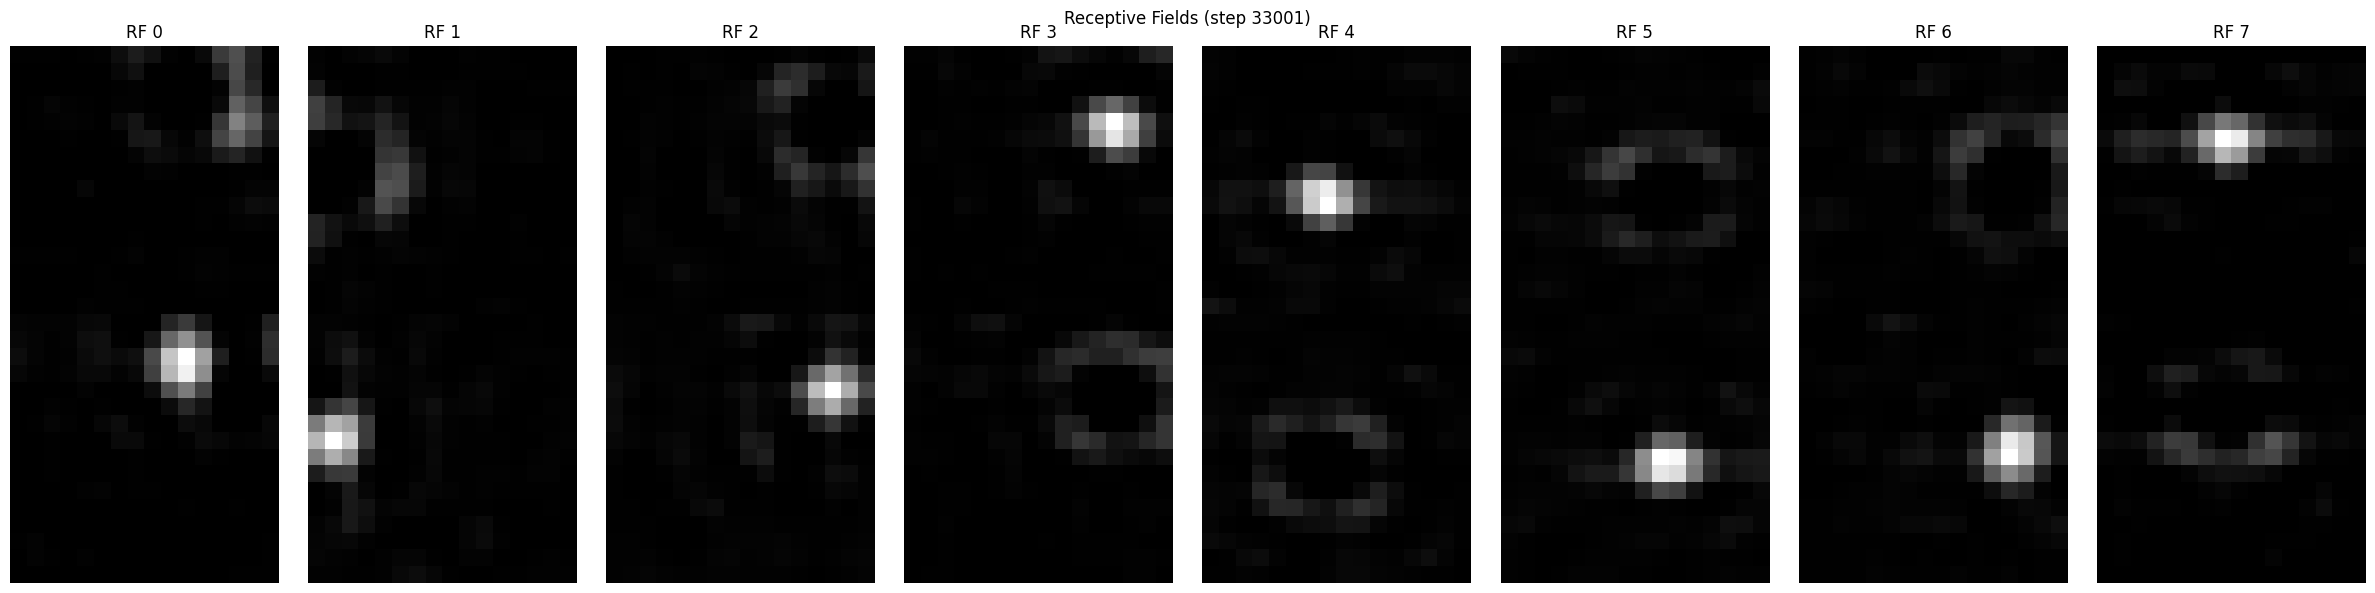

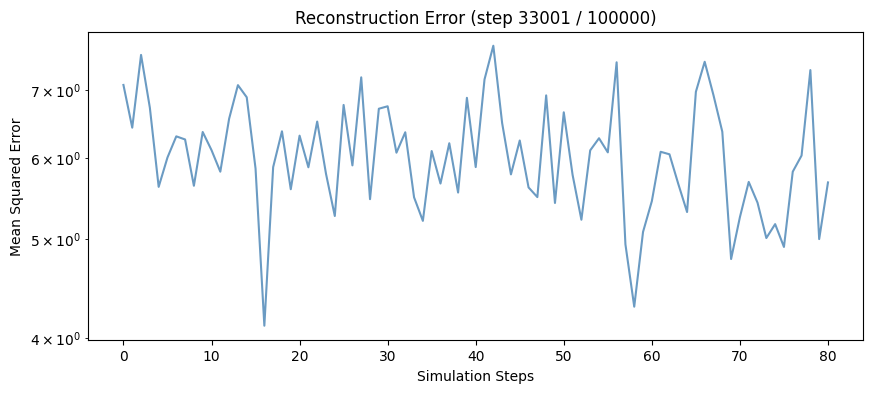

In [ ]:
#select number of steps for the simulation
num_steps = 100000
num_tests = 10

fig, ax = plt.subplots(figsize=(10, 4))

#network.lr_w = 0.0005
#network.lr_m = 0.001
for i in range(num_steps):
    if i % 1000 == 0:
        print(f"Iteration {i}")
        examples = []
        examples_input = []
        errors = []
        for j in range(num_tests):
            gen.set_random_position()
            frame = gen.get_current_frame().copy()
            onoff_frame = 1 * np.vstack([frame * (frame > 0), -frame * (frame < 0)])
            x = onoff_frame.flatten()
            network.reset_network()
            network.update_activations(x, False)
            examples.append(network.y.copy())
            errors.append(np.linalg.norm((x - network.projection().flatten()).reshape(1,-1), ord=2))
            examples_input.append(network.w @ x)
        synaptic_input_distance_from_identity_perceptron.append(np.linalg.norm(np.cov(np.array(examples_input), rowvar=False) - np.eye(network.m.shape[0]), ord='fro'))
        current_second_moment_estimate = np.cov(np.array(examples), rowvar=False)
        distance_from_identity_perceptron.append(np.linalg.norm(network.m - np.eye(network.m.shape[0]), ord='fro'))
        consistency_error_perceptron.append(np.linalg.norm((network.w @ network.w.T) - (current_second_moment_estimate), ord='fro'))
        second_moment_estimate_perceptron.append(np.linalg.norm(current_second_moment_estimate - np.eye(network.m.shape[0]), ord='fro'))
        mse_error_perceptron.append(np.mean(errors))
        clear_output(wait=True)
        ax.cla()
        ax.semilogy(np.array(mse_error_perceptron), alpha=0.8, color='steelblue')
        ax.set_title(f"Reconstruction Error (step {i + 1} / {num_steps})")
        ax.set_xlabel("Simulation Steps")
        ax.set_ylabel("Mean Squared Error")
        # Plot a few receptive fields during training
        num_show = min(8, network.w.shape[0])
        fig_rf, rf_axes = plt.subplots(1, num_show, figsize=(3 * num_show, 6))
        if num_show == 1:
            rf_axes = [rf_axes]

        sorted_indices = np.flip(np.argsort(np.linalg.norm(network.w, axis=1)))[::-1]  # Sort by norm of weights
        for j in range(num_show):
            rf_img = network.w[sorted_indices[j]].reshape(gen.x_size*2, gen.y_size)
            vmax = np.max(np.abs(rf_img))
            rf_axes[j].imshow(rf_img, cmap='gray', vmin=0, vmax=vmax)
            rf_axes[j].set_title(f"RF {j}")
            rf_axes[j].axis("off")

        fig_rf.suptitle(f"Receptive Fields (step {i + 1})")
        plt.tight_layout()
        display(fig_rf)
        plt.close(fig_rf)
        display(fig)

    gen.set_random_position()
    frame = gen.get_current_frame().copy()
    onoff_frame = 1 * np.vstack([frame * (frame > 0), -frame * (frame < 0)])
    x = onoff_frame.flatten()
    network.reset_activations()
    network.update_activations(x, True)
    network.update_parameters(['m', 'w'])

activity = []
for i in range(num_tests):
    gen.set_random_position()
    frame = gen.get_current_frame().copy()
    onoff_frame = 1 * np.vstack([frame * (frame > 0), -frame * (frame < 0)])
    network.reset_activations()
    network.update_activations(onoff_frame, False)
    activity.append(network.y.copy())

plt.scatter(np.array(activity)[:, 0], np.array(activity)[:, 1])
inverse_m = np.linalg.inv(network.m)
plt.quiver(
    0, 0, inverse_m[0,0], inverse_m[1,0],                       # Starting point (0,0) and vector components (u, v)
    angles='xy', scale_units='xy', scale=0.5,  # Keeps vector scaling 1:1 with plot axes
    color='crimson', width=0.012,
)

plt.quiver(
    0, 0, inverse_m[0,1], inverse_m[1,1],                       # Starting point (0,0) and vector components (u, v)
    angles='xy', scale_units='xy', scale=0.5,  # Keeps vector scaling 1:1 with plot axes
    color='crimson', width=0.012,
)
plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.show()

plt.plot(distance_from_identity_perceptron)
plt.xlabel('Iterations')
plt.ylabel('Distance from Identity')
plt.show()

plt.plot(consistency_error_perceptron)
plt.xlabel('Iterations')
plt.ylabel('Consistency Error')
plt.show()

plt.plot(second_moment_estimate_perceptron)
plt.xlabel('Iterations')
plt.ylabel('Output distance from Identity')
plt.show()

plt.plot(mse_error_perceptron)
plt.xlabel('Iterations')
plt.ylabel('MSE Error')
plt.show()

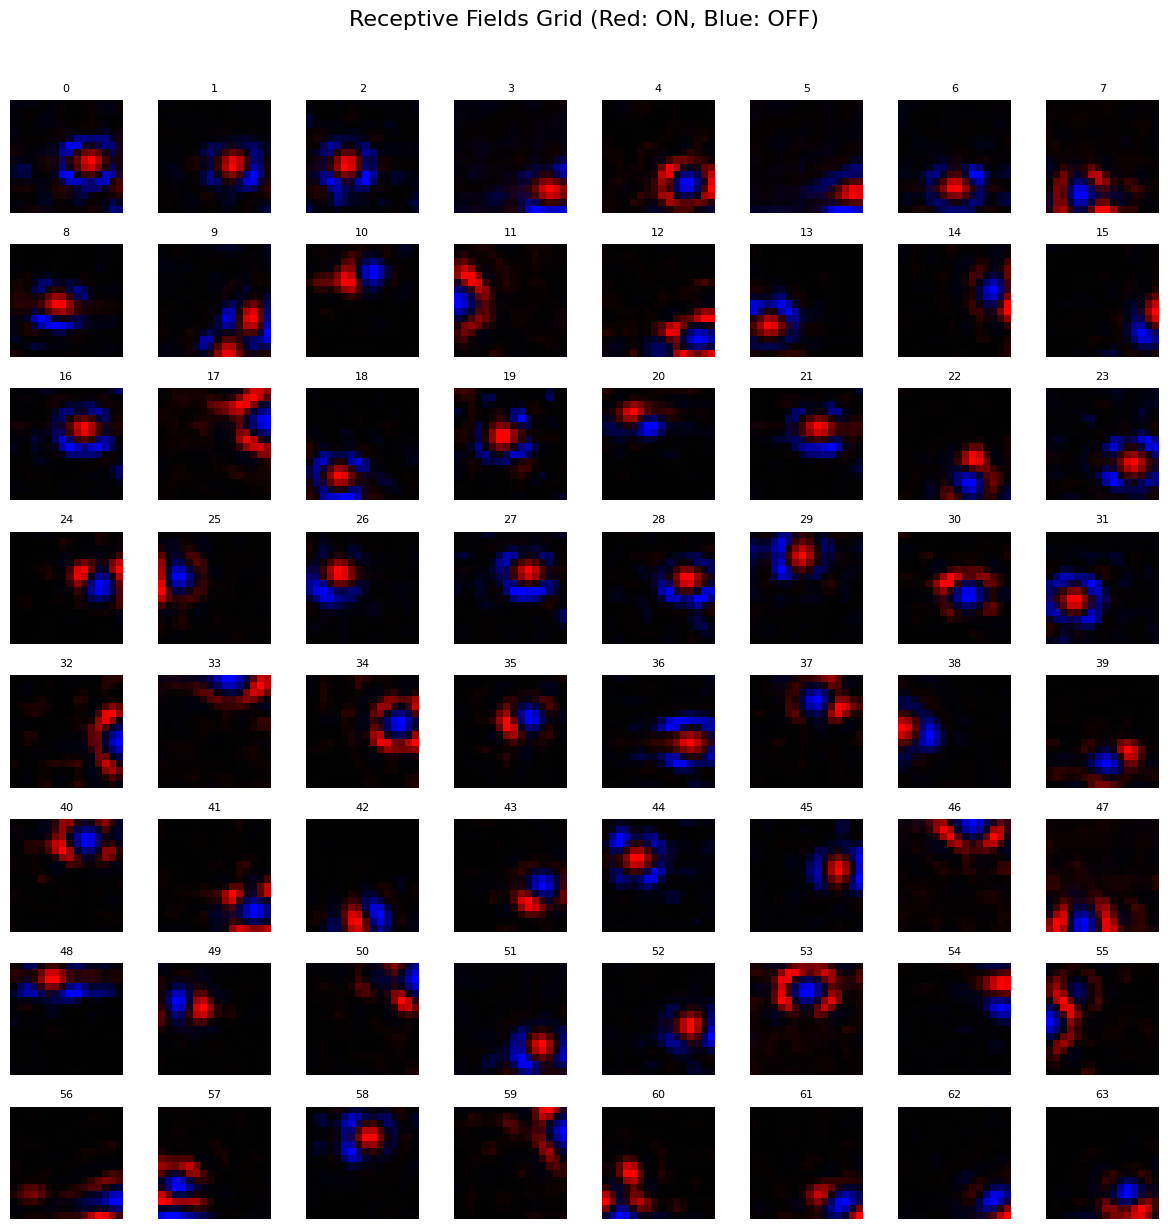

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Configure an 8x8 grid of receptive fields
rows, cols = 8, 8
num_show = min(rows * cols, network.w.shape[0])
fig, axes = plt.subplots(rows, cols, figsize=(12, 12))

# Sort receptive fields by their weight norm (using the trained 'network' object)
sorted_indices = np.flip(np.argsort(np.linalg.norm(network.w, axis=1)))[::-1]

for i in range(rows):
    for j in range(cols):
        idx = i * cols + j
        ax = axes[i, j]
        if idx < num_show:
            # Extract weight vector
            rf_weight = network.w[sorted_indices[idx]]

            # Reshape back to (2 * x_size, y_size) where the top half is ON and the bottom half is OFF
            rf_img = rf_weight.reshape(gen.x_size * 2, gen.y_size)

            # Split into ON and OFF channels
            on_channel = rf_img[:gen.x_size, :]
            off_channel = rf_img[gen.x_size:, :]

            # Normalize each channel individually to [0, 1] for visualization
            max_on = np.max(on_channel) if np.max(on_channel) > 0 else 1.0
            max_off = np.max(off_channel) if np.max(off_channel) > 0 else 1.0

            norm_on = on_channel / max_on
            norm_off = off_channel / max_off

            # Create an RGB image where Red = ON, Blue = OFF, Green = 0
            rgb_img = np.zeros((gen.x_size, gen.y_size, 3))
            rgb_img[..., 0] = norm_on   # Red channel
            rgb_img[..., 2] = norm_off  # Blue channel

            ax.imshow(rgb_img)
            ax.set_title(f"{idx}", fontsize=8)
        ax.axis("off")

fig.suptitle("Receptive Fields Grid (Red: ON, Blue: OFF)", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

## Hebbian Network

Here we initialize and train a network with 500 units that updates the feed-forward weights according to the Hebbian rule.

In [ ]:
#create a linear network with 50 units and change the w_rule rule accordingly (hebbian, bcm_abs, perceptron)
network_params = LateralInhibitoryLayer.default_hparams((gen.x_size*2, gen.y_size, 1))
network_params['activation'] = 'relu'
network_params['num_units_y'] = 500
network_params['gradient'] = 'voltage-jax'
network_params['w_update'] = 'hebbian'
network_params['w_rectify'] = True
network_params['w_seed'] = 42
network_params['w_init'] = 'random'
network_params['w_lr'] = 0.0005
network_params['m_update'] = 'hebbian'
network_params['m_rectify'] = True
network_params['m_init'] = 'random'
network_params['m_lr'] = 0.001
network_params['num_steps'] = 1000
network_params['step'] = 0.01
network_params['normalize_input'] = True
network_params['normalize_w_weights'] = True
network = LateralInhibitoryLayer(network_params)

#save results
synaptic_input_distance_from_identity_hebbian = []
distance_from_identity_hebbian = []
consistency_error_hebbian = []
second_moment_estimate_hebbian = []
mse_error_hebbian = []

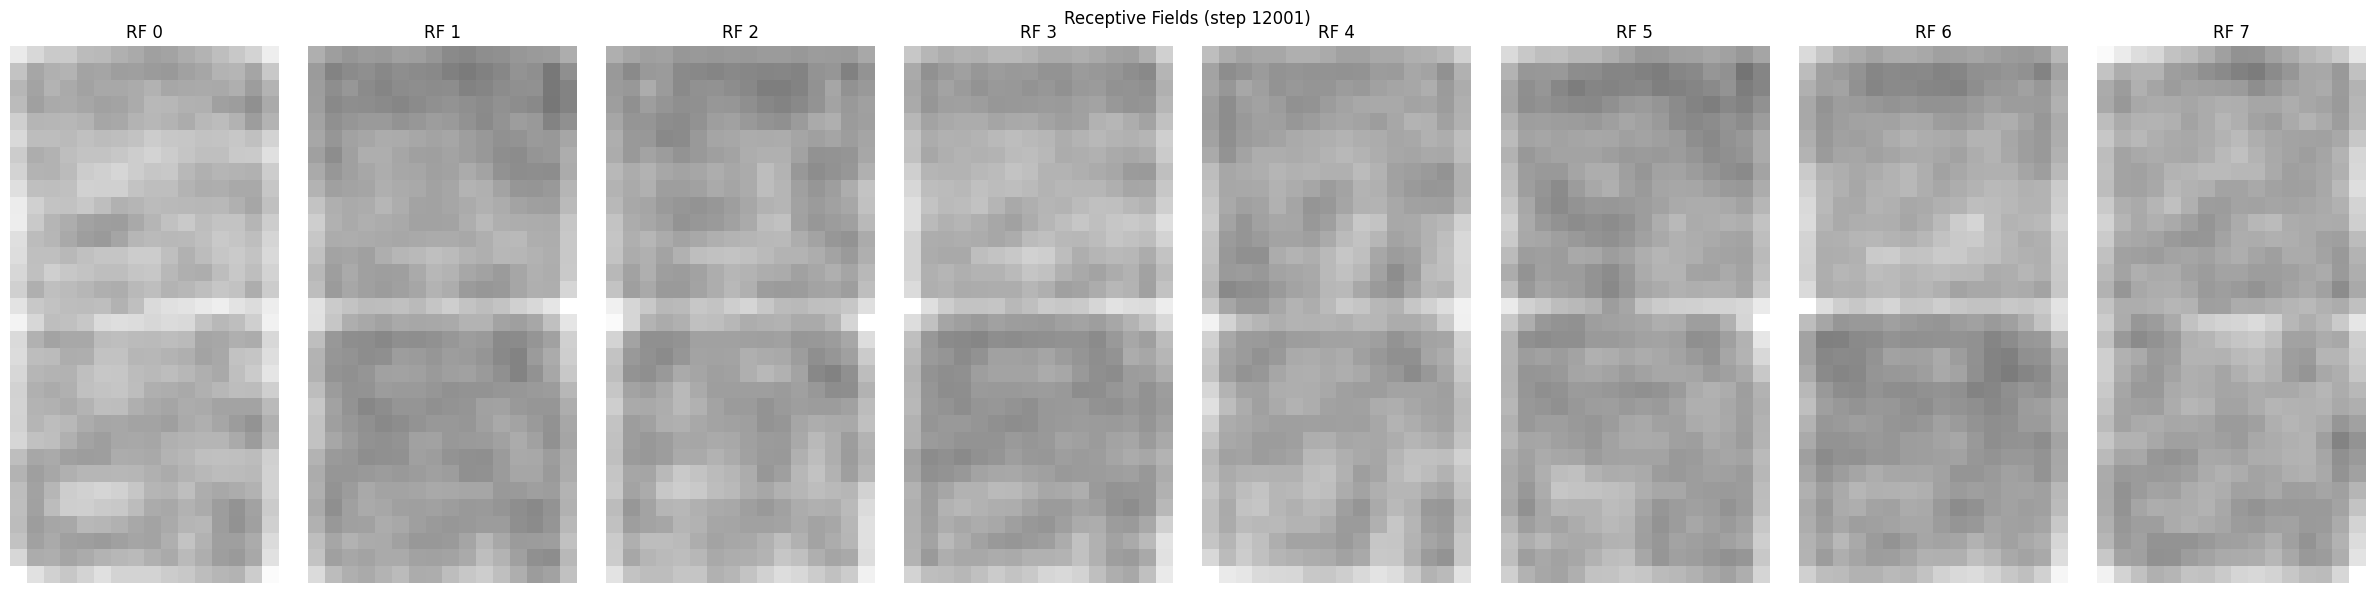

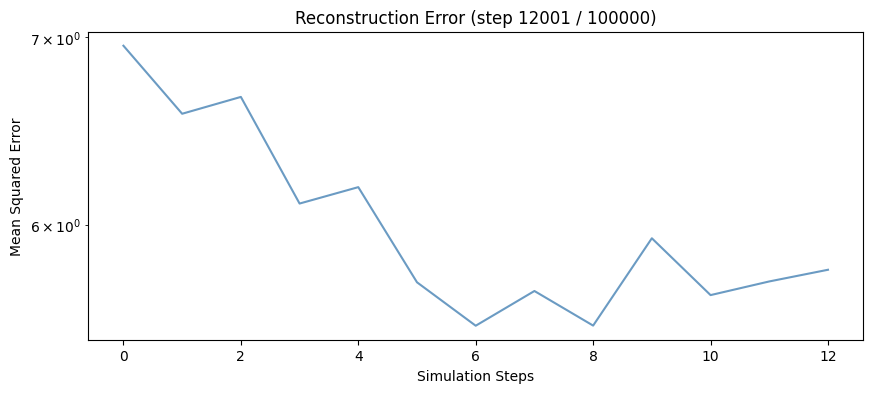

Training Progress:  13%|█▎        | 12895/100000 [11:55<1:13:18, 19.80it/s]

In [ ]:
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

# select hyperparameters for the simulation
num_steps = 100000

fig, ax = plt.subplots(figsize=(10, 4))

# network.lr_w = 0.0005
# network.lr_m = 0.001
for i in tqdm(range(num_steps), desc="Training Progress"):
    if i % 1000 == 0:
        examples = []
        examples_input = []
        errors = []
        for j in range(100):
            gen.set_random_position()
            frame = gen.get_current_frame().copy()
            onoff_frame = 1 * np.vstack([frame * (frame > 0), -frame * (frame < 0)])
            x = onoff_frame.flatten()
            network.reset_network()
            network.update_activations(x, False)
            examples.append(network.y.copy())
            errors.append(np.linalg.norm((x - network.projection().flatten()).reshape(1, -1), ord=2))
            examples_input.append(network.w @ x)
        synaptic_input_distance_from_identity_hebbian.append(np.linalg.norm(np.cov(np.array(examples_input), rowvar=False) - np.eye(network.m.shape[0]), ord='fro'))
        current_second_moment_estimate = np.cov(np.array(examples), rowvar=False)
        distance_from_identity_hebbian.append(np.linalg.norm(network.m - np.eye(network.m.shape[0]), ord='fro'))
        consistency_error_hebbian.append(np.linalg.norm((network.w @ network.w.T) - (current_second_moment_estimate), ord='fro'))
        second_moment_estimate_hebbian.append(np.linalg.norm(current_second_moment_estimate - np.eye(network.m.shape[0]), ord='fro'))
        mse_error_hebbian.append(np.mean(errors))

        clear_output(wait=True)
        ax.cla()
        ax.semilogy(np.array(mse_error_hebbian), alpha=0.8, color='steelblue')
        ax.set_title(f"Reconstruction Error (step {i + 1} / {num_steps})")
        ax.set_xlabel("Simulation Steps")
        ax.set_ylabel("Mean Squared Error")

        # Plot a few receptive fields during training
        num_show = min(8, network.w.shape[0])
        fig_rf, rf_axes = plt.subplots(1, num_show, figsize=(3 * num_show, 6))
        if num_show == 1:
            rf_axes = [rf_axes]

        sorted_indices = np.flip(np.argsort(np.linalg.norm(network.w, axis=1)))[::-1]  # Sort by norm of weights
        for j in range(num_show):
            rf_img = network.w[sorted_indices[j]].reshape(gen.x_size * 2, gen.y_size)
            vmax = np.max(np.abs(rf_img))
            rf_axes[j].imshow(rf_img, cmap='gray', vmin=0, vmax=vmax)
            rf_axes[j].set_title(f"RF {j}")
            rf_axes[j].axis("off")

        fig_rf.suptitle(f"Receptive Fields (step {i + 1})")
        plt.tight_layout()
        display(fig_rf)
        plt.close(fig_rf)
        display(fig)

    gen.set_random_position()
    frame = gen.get_current_frame().copy()
    onoff_frame = 1 * np.vstack([frame * (frame > 0), -frame * (frame < 0)])
    x = onoff_frame.flatten()
    network.reset_activations()
    network.update_activations(x, True)
    network.update_parameters(['m', 'w'])

activity = []
for i in range(150):
    gen.set_random_position()
    frame = gen.get_current_frame().copy()
    onoff_frame = 1 * np.vstack([frame * (frame > 0), -frame * (frame < 0)])
    network.reset_activations()
    network.update_activations(onoff_frame, False)
    activity.append(network.y.copy())

plt.scatter(np.array(activity)[:, 0], np.array(activity)[:, 1])
inverse_m = np.linalg.inv(network.m)
plt.quiver(
    0, 0, inverse_m[0, 0], inverse_m[1, 0],
    angles='xy', scale_units='xy', scale=0.5,
    color='crimson', width=0.012,
)

plt.quiver(
    0, 0, inverse_m[0, 1], inverse_m[1, 1],
    angles='xy', scale_units='xy', scale=0.5,
    color='crimson', width=0.012,
)
plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.show()

plt.plot(distance_from_identity_hebbian)
plt.xlabel('Iterations')
plt.ylabel('Distance from Identity')
plt.show()

plt.plot(consistency_error_hebbian)
plt.xlabel('Iterations')
plt.ylabel('Consistency Error')
plt.show()

plt.plot(second_moment_estimate_hebbian)
plt.xlabel('Iterations')
plt.ylabel('Output distance from Identity')
plt.show()

plt.plot(mse_error_hebbian)
plt.xlabel('Iterations')
plt.ylabel('MSE Error')
plt.show()

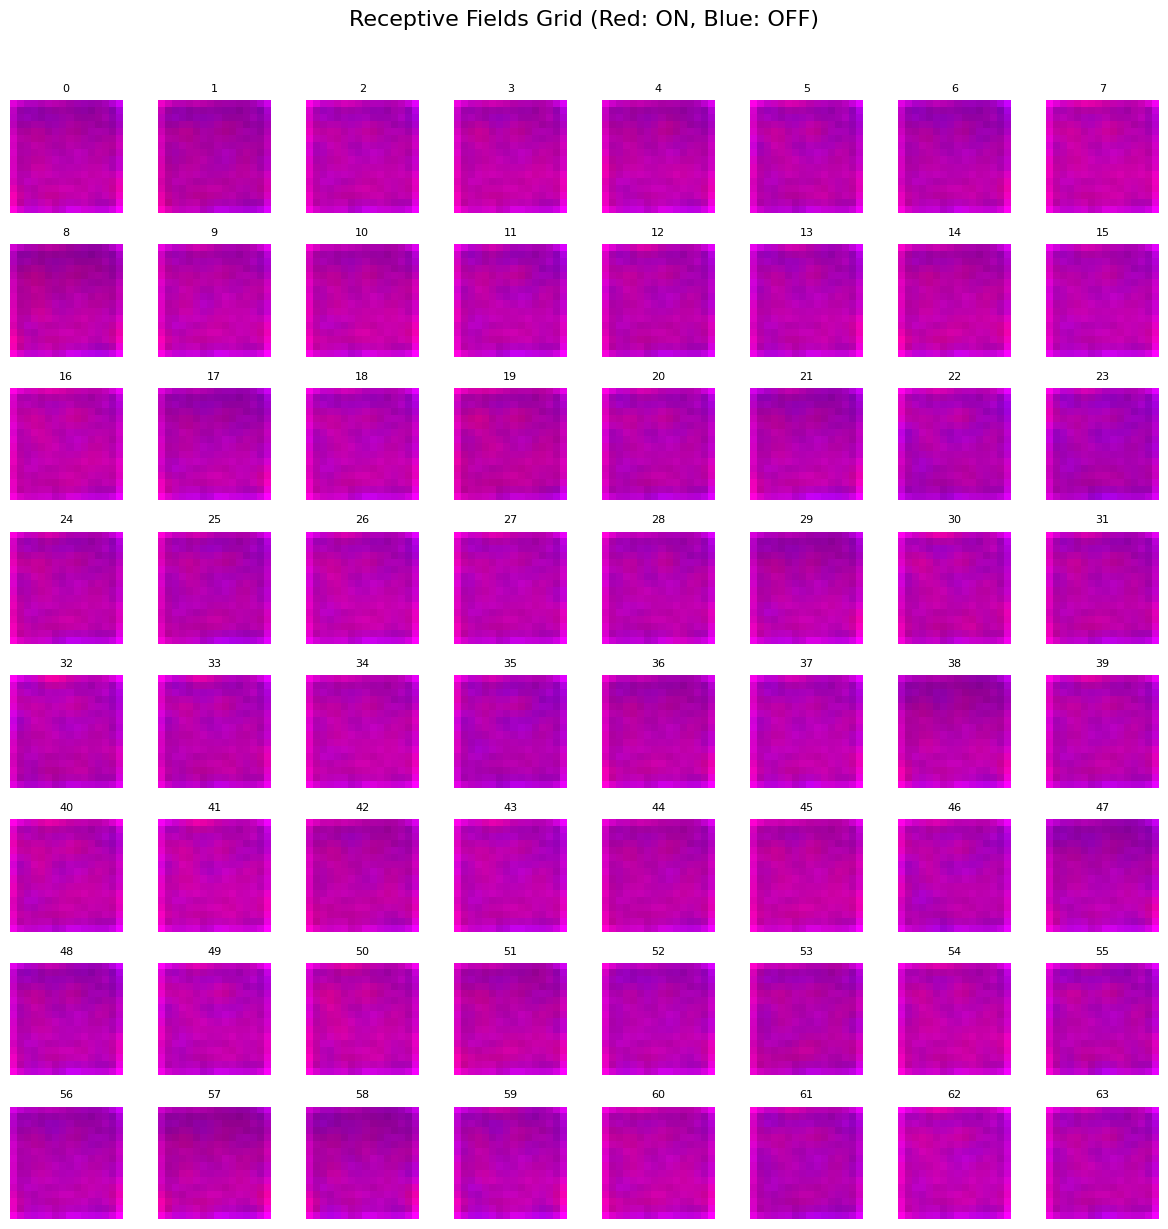

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Configure an 8x8 grid of receptive fields
rows, cols = 8, 8
num_show = min(rows * cols, network.w.shape[0])
fig, axes = plt.subplots(rows, cols, figsize=(12, 12))

# Sort receptive fields by their weight norm (using the trained 'network' object)
sorted_indices = np.flip(np.argsort(np.linalg.norm(network.w, axis=1)))[::-1]

for i in range(rows):
    for j in range(cols):
        idx = i * cols + j
        ax = axes[i, j]
        if idx < num_show:
            # Extract weight vector
            rf_weight = network.w[sorted_indices[idx]]

            # Reshape back to (2 * x_size, y_size) where the top half is ON and the bottom half is OFF
            rf_img = rf_weight.reshape(gen.x_size * 2, gen.y_size)

            # Split into ON and OFF channels
            on_channel = rf_img[:gen.x_size, :]
            off_channel = rf_img[gen.x_size:, :]

            # Normalize each channel individually to [0, 1] for visualization
            max_on = np.max(on_channel) if np.max(on_channel) > 0 else 1.0
            max_off = np.max(off_channel) if np.max(off_channel) > 0 else 1.0

            norm_on = on_channel / max_on
            norm_off = off_channel / max_off

            # Create an RGB image where Red = ON, Blue = OFF, Green = 0
            rgb_img = np.zeros((gen.x_size, gen.y_size, 3))
            rgb_img[..., 0] = norm_on   # Red channel
            rgb_img[..., 2] = norm_off  # Blue channel

            ax.imshow(rgb_img)
            ax.set_title(f"{idx}", fontsize=8)
        ax.axis("off")

fig.suptitle("Receptive Fields Grid (Red: ON, Blue: OFF)", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

## BCM network

Here we initialize and train a network with 500 units that updates the feed-forward weights according to the BCM rule.

In [ ]:
#create a linear network with 50 units and change the w_rule rule accordingly (hebbian, bcm_abs, perceptron)
network_params = LateralInhibitoryLayer.default_hparams((gen.x_size*2, gen.y_size, 1))
network_params['activation'] = 'relu'
network_params['num_units_y'] = 500
network_params['gradient'] = 'voltage-jax'
network_params['w_update'] = 'bcm_abs'
network_params['w_rectify'] = True
network_params['w_seed'] = 42
network_params['w_init'] = 'random'
network_params['w_dynamic'] = True
network_params['m_update'] = 'hebbian'
network_params['m_rectify'] = False
network_params['m_init'] = 'random'
network_params['m_dynamic'] = True
network_params['num_steps'] = 500
network_params['step'] = 0.01
network_params['normalize_input'] = True
network_params['normalize_w_weights'] = True
network = LateralInhibitoryLayer(network_params)

#save results
synaptic_input_distance_from_identity_hebbian = []
distance_from_identity_hebbian = []
consistency_error_hebbian = []
second_moment_estimate_hebbian = []
mse_error_hebbian = []

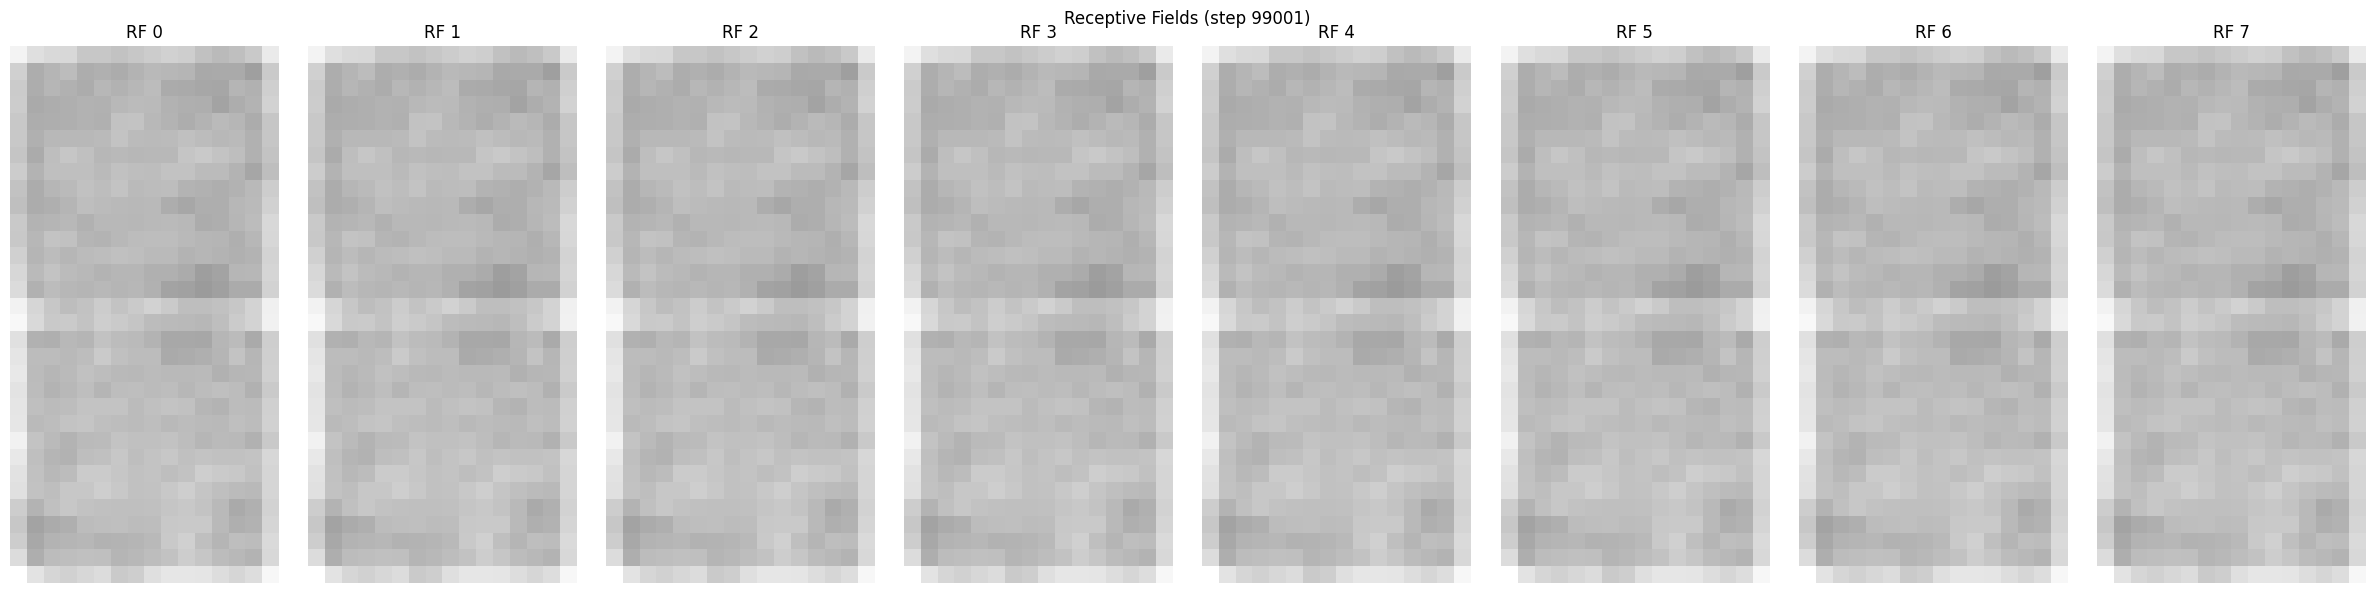

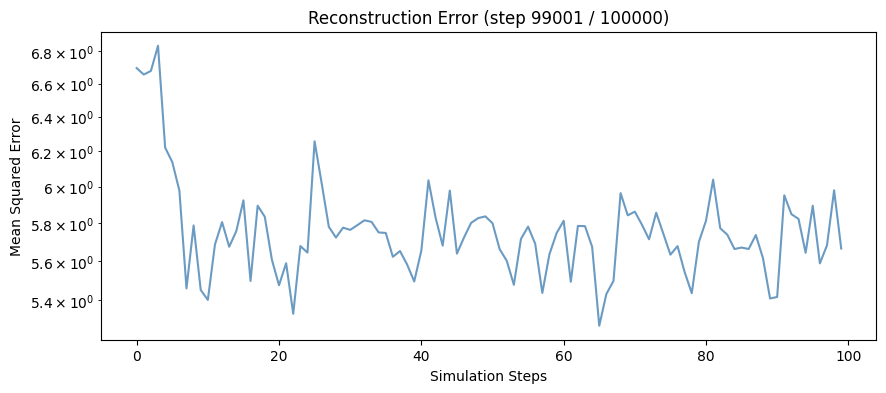

/tmp/ipykernel_3407/1605676404.py:87: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(-5, 5)


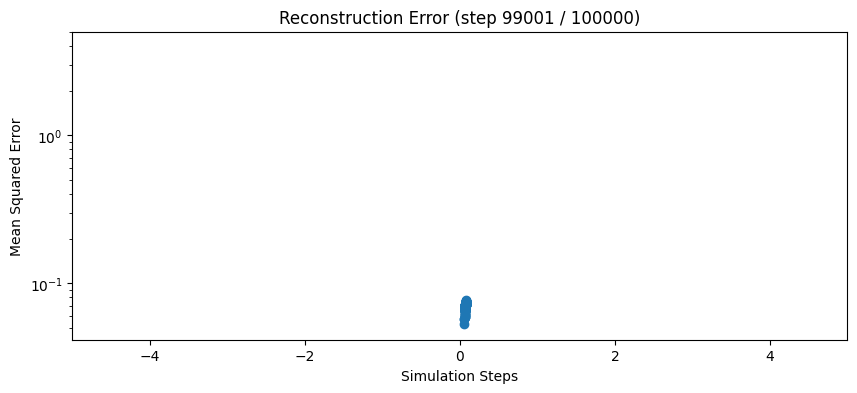

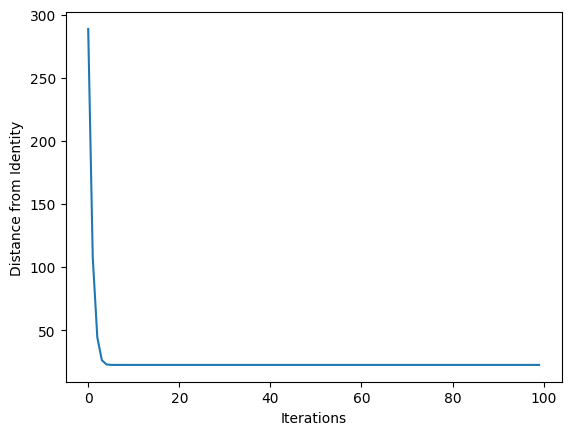

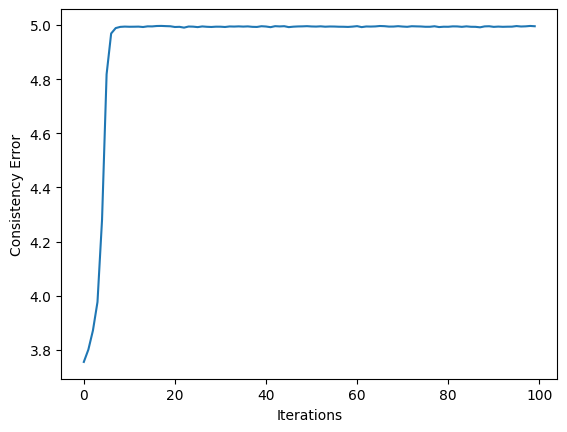

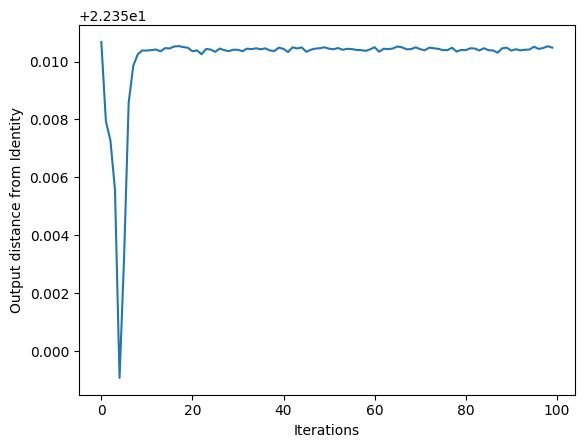

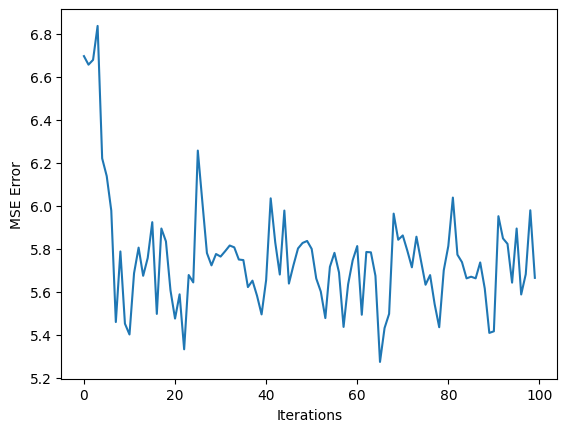

In [ ]:
#select hyperparameters for the simulation
num_steps = 100000

fig, ax = plt.subplots(figsize=(10, 4))

#network.lr_w = 0.0005
#network.lr_m = 0.001
for i in range(num_steps):
    if i % 1000 == 0:
        print(f"Iteration {i}")
        examples = []
        examples_input = []
        errors = []
        for j in range(100):
            gen.set_random_position()
            frame = gen.get_current_frame().copy()
            onoff_frame = 1 * np.vstack([frame * (frame > 0), -frame * (frame < 0)])
            x = onoff_frame.flatten()
            network.reset_network()
            network.update_activations(x, False)
            examples.append(network.y.copy())
            errors.append(np.linalg.norm((x - network.projection().flatten()).reshape(1,-1), ord=2))
            examples_input.append(network.w @ x)
        synaptic_input_distance_from_identity_hebbian.append(np.linalg.norm(np.cov(np.array(examples_input), rowvar=False) - np.eye(network.m.shape[0]), ord='fro'))
        current_second_moment_estimate = np.cov(np.array(examples), rowvar=False)
        distance_from_identity_hebbian.append(np.linalg.norm(network.m - np.eye(network.m.shape[0]), ord='fro'))
        consistency_error_hebbian.append(np.linalg.norm((network.w @ network.w.T) - (current_second_moment_estimate), ord='fro'))
        second_moment_estimate_hebbian.append(np.linalg.norm(current_second_moment_estimate - np.eye(network.m.shape[0]), ord='fro'))
        mse_error_hebbian.append(np.mean(errors))
        clear_output(wait=True)
        ax.cla()
        ax.semilogy(np.array(mse_error_hebbian), alpha=0.8, color='steelblue')
        ax.set_title(f"Reconstruction Error (step {i + 1} / {num_steps})")
        ax.set_xlabel("Simulation Steps")
        ax.set_ylabel("Mean Squared Error")
        # Plot a few receptive fields during training
        num_show = min(8, network.w.shape[0])
        fig_rf, rf_axes = plt.subplots(1, num_show, figsize=(3 * num_show, 6))
        if num_show == 1:
            rf_axes = [rf_axes]

        sorted_indices = np.flip(np.argsort(np.linalg.norm(network.w, axis=1)))[::-1]  # Sort by norm of weights
        for j in range(num_show):
            rf_img = network.w[sorted_indices[j]].reshape(gen.x_size*2, gen.y_size)
            vmax = np.max(np.abs(rf_img))
            rf_axes[j].imshow(rf_img, cmap='gray', vmin=0, vmax=vmax)
            rf_axes[j].set_title(f"RF {j}")
            rf_axes[j].axis("off")

        fig_rf.suptitle(f"Receptive Fields (step {i + 1})")
        plt.tight_layout()
        display(fig_rf)
        plt.close(fig_rf)
        display(fig)

    gen.set_random_position()
    frame = gen.get_current_frame().copy()
    onoff_frame = 1 * np.vstack([frame * (frame > 0), -frame * (frame < 0)])
    x = onoff_frame.flatten()
    network.reset_activations()
    network.update_activations(x, True)
    network.update_parameters(['m', 'w'])

activity = []
for i in range(150):
    gen.set_random_position()
    frame = gen.get_current_frame().copy()
    onoff_frame = 1 * np.vstack([frame * (frame > 0), -frame * (frame < 0)])
    network.reset_activations()
    network.update_activations(onoff_frame, False)
    activity.append(network.y.copy())

plt.scatter(np.array(activity)[:, 0], np.array(activity)[:, 1])
inverse_m = np.linalg.inv(network.m)
plt.quiver(
    0, 0, inverse_m[0,0], inverse_m[1,0],                       # Starting point (0,0) and vector components (u, v)
    angles='xy', scale_units='xy', scale=0.5,  # Keeps vector scaling 1:1 with plot axes
    color='crimson', width=0.012,
)

plt.quiver(
    0, 0, inverse_m[0,1], inverse_m[1,1],                       # Starting point (0,0) and vector components (u, v)
    angles='xy', scale_units='xy', scale=0.5,  # Keeps vector scaling 1:1 with plot axes
    color='crimson', width=0.012,
)
plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.show()

plt.plot(distance_from_identity_hebbian)
plt.xlabel('Iterations')
plt.ylabel('Distance from Identity')
plt.show()

plt.plot(consistency_error_hebbian)
plt.xlabel('Iterations')
plt.ylabel('Consistency Error')
plt.show()

plt.plot(second_moment_estimate_hebbian)
plt.xlabel('Iterations')
plt.ylabel('Output distance from Identity')
plt.show()

plt.plot(mse_error_hebbian)
plt.xlabel('Iterations')
plt.ylabel('MSE Error')
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Configure an 8x8 grid of receptive fields
rows, cols = 8, 8
num_show = min(rows * cols, network.w.shape[0])
fig, axes = plt.subplots(rows, cols, figsize=(12, 12))

# Sort receptive fields by their weight norm (using the trained 'network' object)
sorted_indices = np.flip(np.argsort(np.linalg.norm(network.w, axis=1)))[::-1]

for i in range(rows):
    for j in range(cols):
        idx = i * cols + j
        ax = axes[i, j]
        if idx < num_show:
            # Extract weight vector
            rf_weight = network.w[sorted_indices[idx]]

            # Reshape back to (2 * x_size, y_size) where the top half is ON and the bottom half is OFF
            rf_img = rf_weight.reshape(gen.x_size * 2, gen.y_size)

            # Split into ON and OFF channels
            on_channel = rf_img[:gen.x_size, :]
            off_channel = rf_img[gen.x_size:, :]

            # Normalize each channel individually to [0, 1] for visualization
            max_on = np.max(on_channel) if np.max(on_channel) > 0 else 1.0
            max_off = np.max(off_channel) if np.max(off_channel) > 0 else 1.0

            norm_on = on_channel / max_on
            norm_off = off_channel / max_off

            # Create an RGB image where Red = ON, Blue = OFF, Green = 0
            rgb_img = np.zeros((gen.x_size, gen.y_size, 3))
            rgb_img[..., 0] = norm_on   # Red channel
            rgb_img[..., 2] = norm_off  # Blue channel

            ax.imshow(rgb_img)
            ax.set_title(f"{idx}", fontsize=8)
        ax.axis("off")

fig.suptitle("Receptive Fields Grid (Red: ON, Blue: OFF)", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()